# Przegląd zdarzeń pogodowych

Celem notebooka jest sprawdzenie, jakie zdarzenia pogodowe występują najczęściej, gdzie są odnotowywane oraz które wiążą się z największymi szacowanymi szkodami. Analiza korzysta z prostych operacji pandas i wykresów Matplotlib.

Dane pochodzą z tabeli szczegółów NOAA Storm Events. Opis kolumn znajduje się w pliku `storm-data-export-format.pdf` w tym folderze. Kwoty szkód w źródle mają skróty, np. `K` oznacza tysiące, a `M` miliony dolarów.

> Wnioski zależą od zakresu pliku CSV. Przekazany obecnie plik `storm_data_sample.csv` ma 3906 rekordów z 2026 roku, więc jest wycinkiem niepełnego roku, a nie reprezentatywnym obrazem wszystkich zdarzeń NOAA. Notebook może później pracować na pełniejszym pliku bez zmiany kodu analizy.

## 1. Wczytanie bibliotek i danych

In [21]:
from pathlib import Path
import calendar
import numpy as np

import pandas as pd
import matplotlib.pyplot as plt

# Obsługa nazwy, której używasz, oraz nazwy aktualnie dostępnego pliku.
possible_paths = [
    Path("storm_data.csv"),
    Path("storm_data_sample.csv"),
]
DATA_PATH = next((path for path in possible_paths if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError("Nie znaleziono storm_data_cleaned.csv ani storm_data_sample.csv. Umieść CSV obok notebooka.")

print(f"Wczytywany plik: {DATA_PATH}")
df = pd.read_csv(DATA_PATH)
print(f"Liczba wierszy: {df.shape[0]}, liczba kolumn: {df.shape[1]}")
df.head()

Wczytywany plik: storm_data.csv
Liczba wierszy: 39062, liczba kolumn: 40


,BEGIN_YEARMONTH,BEGIN_DAY,BEGIN_TIME,END_YEARMONTH,END_DAY,END_TIME,EPISODE_ID,EVENT_ID,STATE,STATE_FIPS,...,BEGIN_AZIMUTH,BEGIN_LOCATION,END_RANGE,END_AZIMUTH,END_LOCATION,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,DATA_SOURCE
0,202604,14,1900,202604,14,1900,210980,1318063,MASSACHUSETTS,25,...,N,BROOKS,0.69,N,BROOKS,42.43,-71.90,42.43,-71.90,CSV
1,202604,14,1910,202604,14,1910,210980,1318061,MASSACHUSETTS,25,...,SW,SOUTH LANCASTER,0.86,SW,SOUTH LANCASTER,42.44,-71.69,42.44,-71.69,CSV
2,202604,14,1909,202604,14,1909,210980,1318062,MASSACHUSETTS,25,...,N,LOVELLVILLE,0.69,N,LOVELLVILLE,42.38,-71.85,42.38,-71.85,CSV
3,202604,14,1855,202604,14,1855,210980,1318064,MASSACHUSETTS,25,...,NNW,TURKEY HILL SHRS,1.47,NNW,TURKEY HILL SHRS,42.35,-71.96,42.35,-71.96,CSV
4,202603,15,1421,202603,15,1421,210240,1312615,TENNESSEE,47,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CSV


## 2. Szybkie poznanie danych

Sprawdzamy nazwy kolumn, typy danych, braki i zakres lat. Plik szczegółów zawiera po jednym rekordzie na zdarzenie lub jego część; `EVENT_ID` identyfikuje zdarzenie.

In [22]:
df.info()

missing_values = df.isna().sum().sort_values(ascending=False)

print("\nProcent brakujących wartości w danych:")
missing_values[missing_values > 0] * 100 / 39062

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39062 entries, 0 to 39061
Data columns (total 40 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   BEGIN_YEARMONTH    39062 non-null  int64  
 1   BEGIN_DAY          39062 non-null  int64  
 2   BEGIN_TIME         39062 non-null  int64  
 3   END_YEARMONTH      39062 non-null  int64  
 4   END_DAY            39062 non-null  int64  
 5   END_TIME           39062 non-null  int64  
 6   EPISODE_ID         39062 non-null  int64  
 7   EVENT_ID           39062 non-null  int64  
 8   STATE              39062 non-null  object 
 9   STATE_FIPS         39062 non-null  int64  
 10  YEAR               39062 non-null  int64  
 11  MONTH_NAME         39062 non-null  object 
 12  EVENT_TYPE         39062 non-null  object 
 13  CZ_TYPE            39062 non-null  object 
 14  CZ_FIPS            39062 non-null  int64  
 15  CZ_NAME            39062 non-null  object 
 16  WFO                390

MAGNITUDE_TYPE     59.684604
MAGNITUDE          45.688905
BEGIN_AZIMUTH      43.986483
END_LON            43.986483
END_LAT            43.986483
BEGIN_LON          43.986483
BEGIN_LAT          43.986483
END_LOCATION       43.986483
END_AZIMUTH        43.986483
END_RANGE          43.986483
BEGIN_LOCATION     43.986483
BEGIN_RANGE        43.986483
DAMAGE_CROPS       26.854744
DAMAGE_PROPERTY    25.636168
dtype: float64

In [23]:
# df['YEAR'].value_counts()

print("Lata w pliku:", sorted(df["YEAR"].dropna().unique()))
print("Liczba stanów/obszarów:", df["STATE"].nunique())
print("Liczba typów zdarzeń:", df["EVENT_TYPE"].nunique())
df[["STATE", "YEAR", "EVENT_TYPE", "DAMAGE_PROPERTY", "DAMAGE_CROPS"]].head()

Lata w pliku: [2026]
Liczba stanów/obszarów: 64
Liczba typów zdarzeń: 46


,STATE,YEAR,EVENT_TYPE,DAMAGE_PROPERTY,DAMAGE_CROPS
0,MASSACHUSETTS,2026,Thunderstorm Wind,1.00K,0.00K
1,MASSACHUSETTS,2026,Thunderstorm Wind,10.00K,0.00K
2,MASSACHUSETTS,2026,Thunderstorm Wind,10.00K,0.00K
3,MASSACHUSETTS,2026,Thunderstorm Wind,1.00K,0.00K
4,TENNESSEE,2026,Strong Wind,1.00K,0.00K


## 3. Przygotowanie pól do analizy

Zamieniamy datę na typ daty oraz kwoty szkód zapisane jako tekst (np. `2.50K`, `1.20M`) na liczby w dolarach. Brak kwoty pozostaje brakiem — nie zakładamy, że oznacza zero szkód.

In [24]:
# Zamienia zapisu kwoty z K/M/B na dolary.
def damage_to_dollars(value):
    if pd.isna(value):
        return float("nan")

    text = str(value).strip().upper()
    multiplier = 1
    if text.endswith("K"):
        multiplier = 1_000
        text = text[:-1]
    elif text.endswith("M"):
        multiplier = 1_000_000
        text = text[:-1]
    elif text.endswith("B"):
        multiplier = 1_000_000_000
        text = text[:-1]

    return np.round(float(text.replace(",", "")) * multiplier)

In [25]:
df["BEGIN_DATE_TIME"] = pd.to_datetime(
    df["BEGIN_DATE_TIME"],
    format="%d-%b-%y %H:%M:%S",
    errors="coerce"
)

# "DAMAGE_PROPERTY" - szkody w mieniu (w dolarach)
# "DAMAGE_CROPS" - szkody w uprawach (w dolarach)

df["DAMAGE_PROPERTY_USD"] = df["DAMAGE_PROPERTY"].apply(damage_to_dollars)
df["DAMAGE_CROPS_USD"] = df["DAMAGE_CROPS"].apply(damage_to_dollars)

df["DAMAGE_PROPERTY_USD"] = df["DAMAGE_PROPERTY_USD"].astype("Int64")
df["DAMAGE_CROPS_USD"] = df["DAMAGE_CROPS_USD"].astype("Int64")


# "INJURIES_DIRECT" - ilość obrażeń bezpośrednio związanych z wydarzeniem
# "INJURIES_INDIRECT" - ilość obrażeń pośrednio związanych z wydarzeniem
# "DEATHS_DIRECT" - ilość zgonów bezpośrednio związanych z wydarzeniem
# "DEATHS_INDIRECT" - ilość zgonów pośrednio związanych z wydarzeniem

count_columns = [
    "INJURIES_DIRECT", "INJURIES_INDIRECT",
    "DEATHS_DIRECT", "DEATHS_INDIRECT"
]
for column in count_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# dodanie kolumn sumujących obrażenia i zgony
df["INJURIES_TOTAL"] = df["INJURIES_DIRECT"] + df["INJURIES_INDIRECT"]
df["DEATHS_TOTAL"] = df["DEATHS_DIRECT"] + df["DEATHS_INDIRECT"]

In [26]:
# df[df[['INJURIES_DIRECT']].notna() & (df[['INJURIES_DIRECT']] > 10)]['INJURIES_DIRECT'].sample(5)
# type(df['INJURIES_DIRECT'])
# type(df[['INJURIES_DIRECT']])
df["DAMAGE_PROPERTY_USD"][(df["DAMAGE_PROPERTY_USD"] % 1 != 0) & (df["DAMAGE_PROPERTY_USD"].notna())]

repr(df["DAMAGE_PROPERTY_USD"].iloc[21026])

'8200000'

In [27]:
cols = ["DAMAGE_PROPERTY_USD", "DAMAGE_CROPS_USD", "INJURIES_TOTAL", "DEATHS_TOTAL"]

# Wyświetla wiersze, w których wszystkie kolumny z listy `cols` mają wartości większe od 0 i nie są puste.
df[df[cols].notna().all(axis=1) & (df[cols] > 0).all(axis=1)][cols]

,DAMAGE_PROPERTY_USD,DAMAGE_CROPS_USD,INJURIES_TOTAL,DEATHS_TOTAL
4576,4500000,20000,24,2
36041,91000000,5000000,5,9


## 4. Jakie zdarzenia pojawiają się najczęściej?

Liczba rekordów opisuje raportowane zdarzenia w aktualnym pliku. Nie jest to prognoza ryzyka ani porównanie liczby zdarzeń do liczby mieszkańców.

In [28]:
events_by_type = df["EVENT_TYPE"].value_counts().head(10).sort_values()
print(events_by_type)

EVENT_TYPE
Cold/Wind Chill              1123
Extreme Cold/Wind Chill      1175
Marine Thunderstorm Wind     1220
Flash Flood                  1709
Winter Weather               1908
Winter Storm                 1957
High Wind                    2610
Drought                      4376
Hail                         5455
Thunderstorm Wind           11388
Name: count, dtype: int64


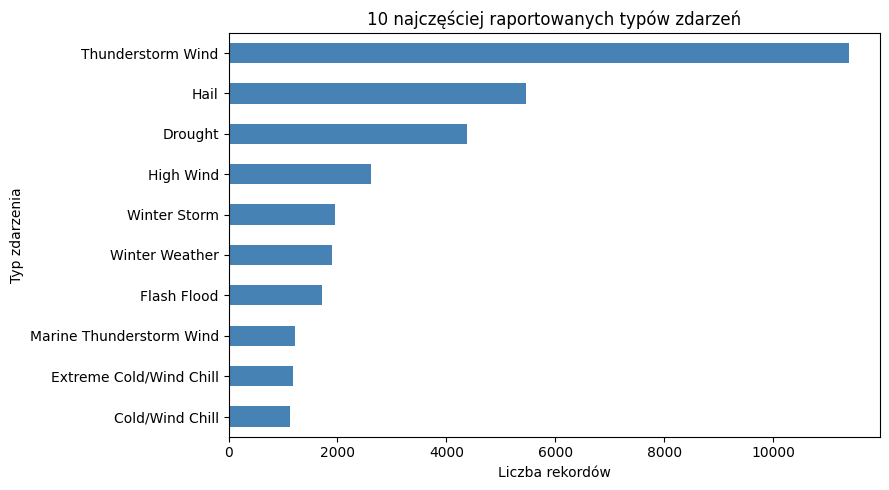

In [29]:
ax = events_by_type.plot(kind="barh", figsize=(9, 5), color="steelblue")
ax.set_title("10 najczęściej raportowanych typów zdarzeń")
ax.set_xlabel("Liczba rekordów")
ax.set_ylabel("Typ zdarzenia")
plt.tight_layout()
plt.show()

In [30]:
events_by_type.sort_values(ascending=False)

EVENT_TYPE
Thunderstorm Wind           11388
Hail                         5455
Drought                      4376
High Wind                    2610
Winter Storm                 1957
Winter Weather               1908
Flash Flood                  1709
Marine Thunderstorm Wind     1220
Extreme Cold/Wind Chill      1175
Cold/Wind Chill              1123
Name: count, dtype: int64

**Pytanie do wniosków:** które typy zdarzeń dominują? Czy wynik może wynikać z tego, że plik obejmuje konkretny rok lub część roku?

## 5. Kiedy odnotowano zdarzenia?

Porządkujemy nazwy miesięcy kalendarzowo, zamiast alfabetycznie.

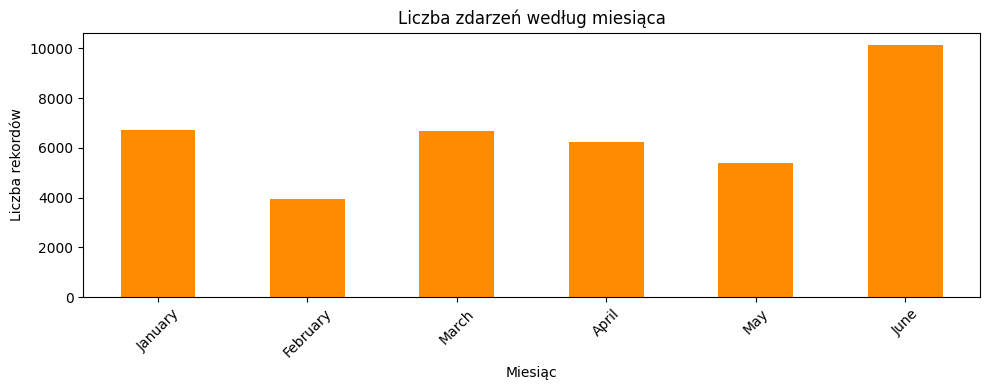

In [31]:
month_order = list(calendar.month_name)[1:]
events_by_month = df["MONTH_NAME"].value_counts().reindex(month_order).dropna()
# events_by_month = df["MONTH_NAME"].value_counts().dropna()

ax = events_by_month.plot(kind="bar", figsize=(10, 4), color="darkorange")
ax.set_title("Liczba zdarzeń według miesiąca")
ax.set_xlabel("Miesiąc")
ax.set_ylabel("Liczba rekordów")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Z których stanach jest najwięcej wpisów?

Pokazujemy 10 stanów z największą liczbą raportów w pliku.

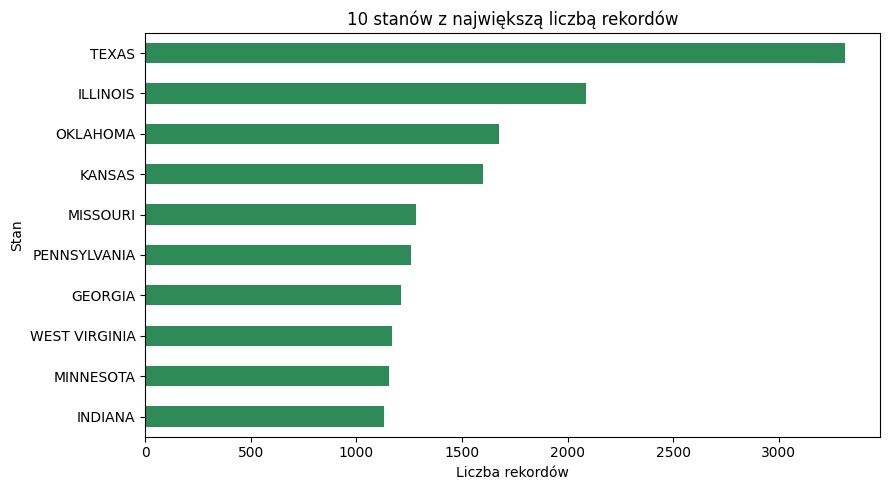

In [32]:
events_by_state = df["STATE"].value_counts().head(10).sort_values()

ax = events_by_state.plot(kind="barh", figsize=(9, 5), color="seagreen")
ax.set_title("10 stanów z największą liczbą rekordów")
ax.set_xlabel("Liczba rekordów")
ax.set_ylabel("Stan")
plt.tight_layout()
plt.show()

## 7. Szacowane szkody materialne

Sumujemy wartości podane przez NOAA dla nieruchomości i upraw. To szacunki raportowane przy zdarzeniach, nie wypłaty ubezpieczeniowe. Brakujące kwoty nie są doliczane jako zero ani uzupełniane.

In [33]:
df.groupby("EVENT_TYPE")['DAMAGE_PROPERTY_USD'].value_counts()

EVENT_TYPE             DAMAGE_PROPERTY_USD
Astronomical Low Tide  0                       82
Avalanche              0                       14
Blizzard               0                      237
                       6100                     2
                       10000                    1
                                             ... 
Winter Weather         5000                     1
                       2000                     1
                       1500                     1
                       500                      1
                       4500000                  1
Name: count, Length: 603, dtype: Int64

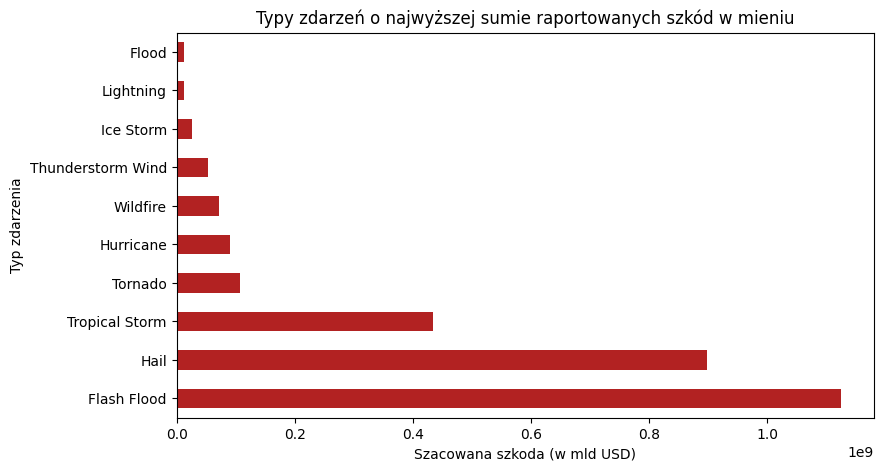

In [34]:
damage_by_type = (
    df.groupby("EVENT_TYPE")["DAMAGE_PROPERTY_USD"]
    .sum(min_count=1)
    .sort_values(ascending=False)
    .head(10)
)
damage_by_type.plot(kind="barh", figsize=(9, 5), color="firebrick")
plt.title("Typy zdarzeń o najwyższej sumie raportowanych szkód w mieniu")
plt.xlabel("Szacowana szkoda (w mld USD)")
plt.ylabel("Typ zdarzenia")
# plt.ticklabel_format(axis="x", style="plain")
plt.show()

In [35]:
damage_by_type.sort_values(ascending=False)[:2]

EVENT_TYPE
Flash Flood    1124929000
Hail            898714860
Name: DAMAGE_PROPERTY_USD, dtype: Int64

In [36]:
damage_by_type.to_frame(name="damage_property_usd").style.format("$ {:,.0f}")

,damage_property_usd
EVENT_TYPE,
Flash Flood,"$ 1,124,929,000"
Hail,"$ 898,714,860"
Tropical Storm,"$ 434,500,000"
Tornado,"$ 106,771,000"
Hurricane,"$ 91,000,000"
Wildfire,"$ 72,088,600"
Thunderstorm Wind,"$ 53,689,250"
Ice Storm,"$ 25,760,000"
Lightning,"$ 12,564,300"


## 8. Zdarzenia związane z obrażeniami i ofiarami

Porównujemy sumy osób rannych i ofiar śmiertelnych odnotowanych bezpośrednio i pośrednio. Wskaźniki te nie są miarą szkód materialnych.

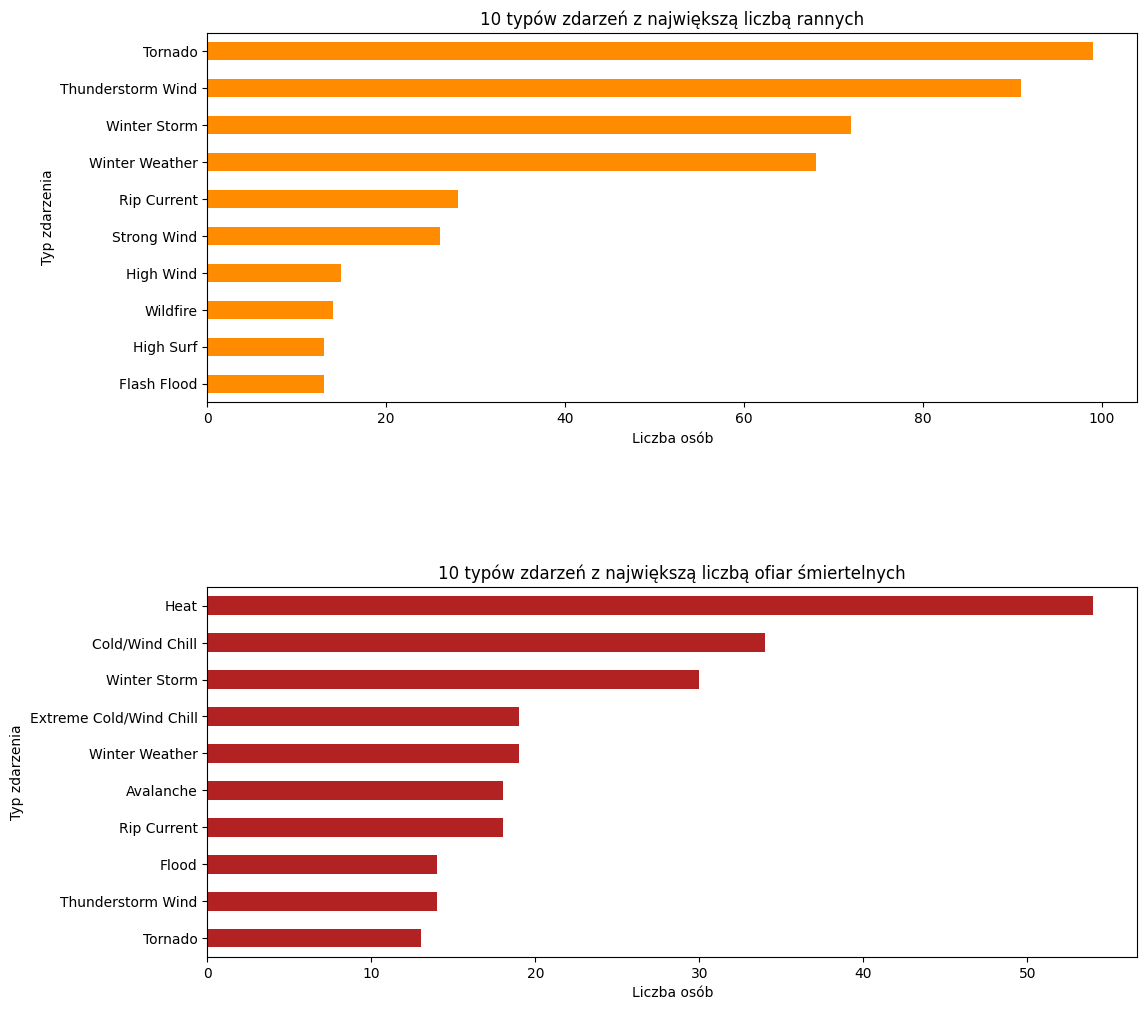

Top 10 typów zdarzeń z największą liczbą rannych:
                   INJURIES_TOTAL
EVENT_TYPE                       
Tornado                        99
Thunderstorm Wind              91
Winter Storm                   72
Winter Weather                 68

Top 10 typów zdarzeń z największą liczbą ofiar śmiertelnych:
                 DEATHS_TOTAL
EVENT_TYPE                   
Heat                       54
Cold/Wind Chill            34
Winter Storm               30
Winter Weather             19


In [37]:
injuries_by_event_type = (
    df.groupby("EVENT_TYPE")[["INJURIES_TOTAL"]]
    .sum()
    .sort_values("INJURIES_TOTAL", ascending=False)
    .head(10)
)

deaths_by_event_type = (
    df.groupby("EVENT_TYPE")[["DEATHS_TOTAL"]]
    .sum()
    .sort_values("DEATHS_TOTAL", ascending=False)
    .head(10)
)

fig, axes = plt.subplots(2, 1, figsize=(32, 5))

injuries_by_event_type.sort_values("INJURIES_TOTAL").plot(kind="barh", figsize=(12, 12), color="darkorange", legend=False, ax=axes[0])
axes[0].set_title("10 typów zdarzeń z największą liczbą rannych")
axes[0].set_xlabel("Liczba osób")
axes[0].set_ylabel("Typ zdarzenia")

deaths_by_event_type.sort_values("DEATHS_TOTAL").plot(kind="barh", figsize=(12, 12), color="firebrick", legend=False, ax=axes[1])
axes[1].set_title("10 typów zdarzeń z największą liczbą ofiar śmiertelnych")
axes[1].set_xlabel("Liczba osób")
axes[1].set_ylabel("Typ zdarzenia")

# plt.tight_layout()
plt.subplots_adjust(hspace=.5)
plt.show()

print("Top 10 typów zdarzeń z największą liczbą rannych:")
print(injuries_by_event_type[:4])
print("\nTop 10 typów zdarzeń z największą liczbą ofiar śmiertelnych:")
print(deaths_by_event_type[:4])


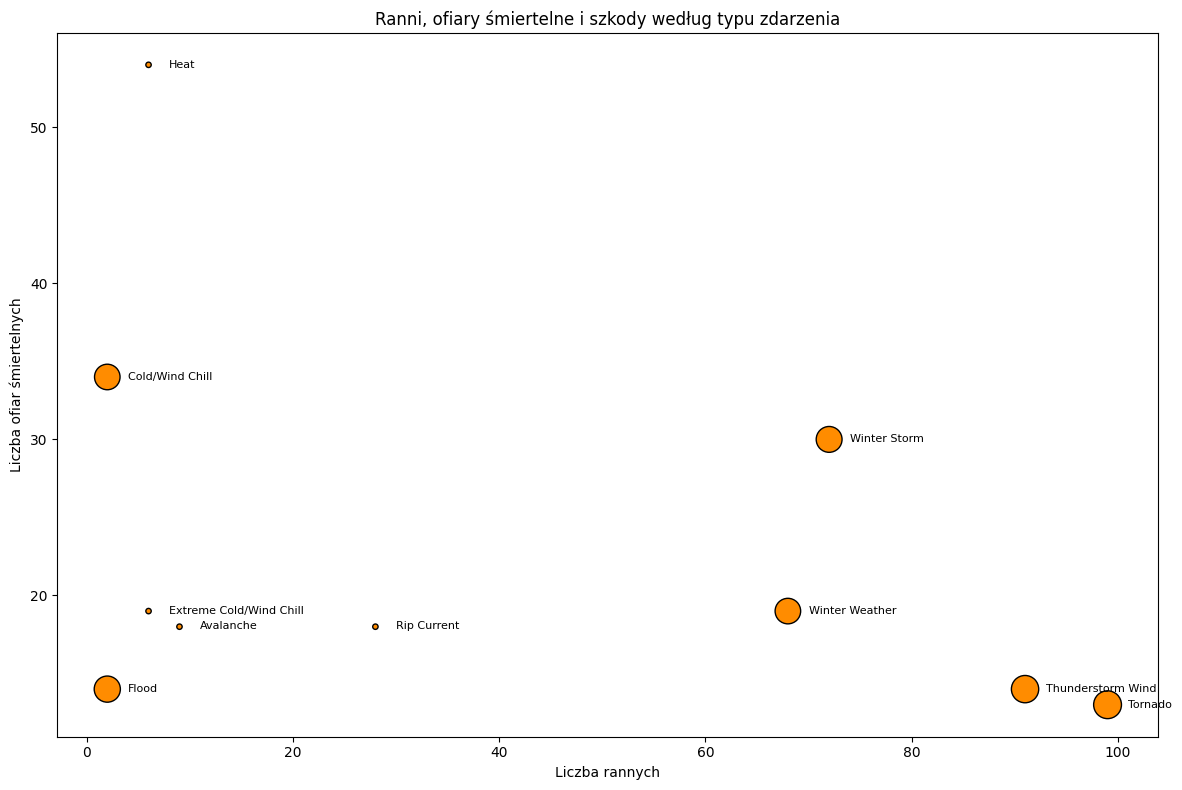

In [38]:
# Podsumowanie danych dla każdego typu zdarzenia
impact_by_type = (
    df.groupby("EVENT_TYPE")
    .agg(
        injuries=("INJURIES_TOTAL", "sum"),
        deaths=("DEATHS_TOTAL", "sum"),
        damage_usd=("DAMAGE_PROPERTY_USD", "sum")
    )
    .reset_index()
)

# Rozmiar punktu zależy od wartości szkód.
# Używam logarytmu, żeby duże szkody nie zdominowały wykresu.
impact_by_type["bubble_size"] = (
    impact_by_type["damage_usd"].fillna(0).clip(lower=0) + 1
).apply(lambda value: 50 * np.log10(value + 1))


impact_by_type = impact_by_type[
    (impact_by_type["deaths"] >= 10)
    # & (impact_by_type["injuries"] >= 10)
    # & (impact_by_type["damage_usd"] >= 10)
]

plt.figure(figsize=(12, 8))

plt.scatter(
    impact_by_type["injuries"],
    impact_by_type["deaths"],
    s=impact_by_type["bubble_size"],
    color="darkorange",
    edgecolor="black"
)

# Dodanie nazwy typu zdarzenia przy każdym punkcie
for index, row in impact_by_type.iterrows():
    plt.annotate(
        row["EVENT_TYPE"],
        (row["injuries"], row["deaths"]),
        xytext=(15, -2),
        textcoords="offset points",
        fontsize=8
    )

plt.title("Ranni, ofiary śmiertelne i szkody według typu zdarzenia")
plt.xlabel("Liczba rannych")
plt.ylabel("Liczba ofiar śmiertelnych")
plt.tight_layout()
plt.show()

## 9. Podsumowanie

> <span style="color:red">**UWAGA!**</span> **Analiza** opiera się na danych z pierwszej połowy bieżącego roku (styczeń - czerwiec 2026)!\
> Nie powinno się tych danych ekspandować na cały rok.

### 1. Który typ zdarzenia jest najczęstszy w analizowanych danych?
Dane pokazują, że **burze z wiatrem** (Thunderstorm Wind) są najczęściej raportowanym typem zdarzenia.

### 2. W których miesiącach jest najwięcej rekordów?
Dane pokazują, że najwięcej rekordów występują w **czerwcu**.


### 3. Który typ zdarzenia ma najwyższą sumę raportowanych szkód w mieniu?
Najczęściej raportowane szkody w mieniu dotyczą **nagła powódź** (Flash Flood) oraz **grad** (Hail)

### 4. Związek między sumą raportowanych szkód a liczbą ofiar?
Wydażenia, które generują wysokie **szkody w mieniu** i jednocześnie:
- znaczącą liczbę **ofiar śmiertelnych**, to: **gwałtowna śnieżyca** (Winter Storm).
- dużą liczbę **rannych**, to: **tornado** (Tornado) oraz **silne porywy wiatru (burze z wiatrem)** (Thunderstorm Wind).